In [1]:
import sys
sys.path.append("..")
import matplotlib.pyplot as plt
import statsmodels.api as sm
from src.data import load_brent_spot
from src.features import log_returns

In notebook aa_forecast1.ipynb, shown that no significant correlation at any lag. Will test again for forecast of horizon = 5.

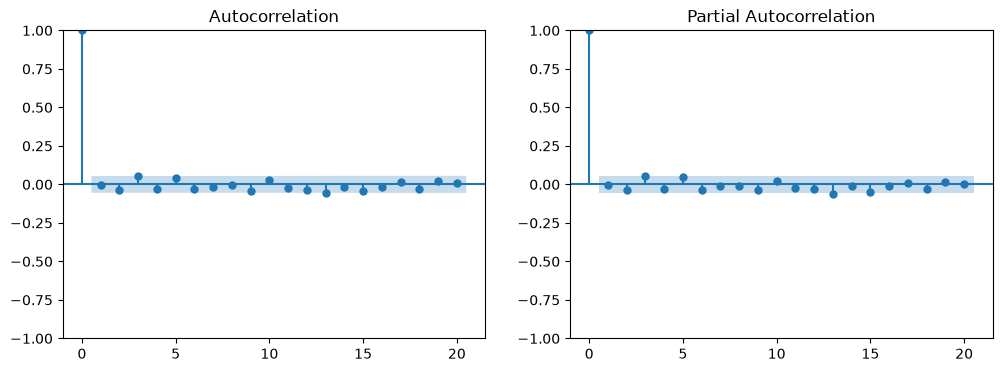

In [2]:
spot = load_brent_spot(start="2000-01-01")
data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

rolling_5_day_returns= data["log_return"].loc[:"2026-09-30"].rolling(5).sum() # each row adds the 5 behind it, then shows as a single 5-day log return
five_day_no_overlap = rolling_5_day_returns.iloc[::5].dropna() #only keeps every 5th row, this ensures no overlap in like day 5 and day 10's return.
# otherwise for example day 5 and day 6's return, would share 4 similar days towards their sums.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sm.graphics.tsa.plot_acf(five_day_no_overlap, lags=20, ax=axes[0])
sm.graphics.tsa.plot_pacf(five_day_no_overlap, lags=20, ax=axes[1])
plt.show()


Close no AR or MA signals. Don't have to consider AR MA family of models. Will keep AR1 for benchmark purposes.

In [3]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from src.data import load_dataset
from src.backtest import walk_forward
from src.models import random_walk_forecast, historical_mean_forecast, ar1_forecast, var_forecast
from src.metrics import compare_models_staggered, accuracy_metrics

data = load_dataset()
PRICES = ["brent_spot", "wti", "usd", "sp500"]  # prices -> log returns
INDICES = ["vix", "ovx", "epu", "gpr"]  # fear/uncertainty indices -> log levels
CHANGES = ["invt_weekly_change"]  # alr in percent -> no need do log diff

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
for col in CHANGES:
    X[col] = data[col]
X = X.dropna()

df_var = X.rename(columns={"brent_spot": "log_return"})
df_var["brent_spot"] = data["brent_spot"]


/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [4]:
STAGES = {
    "S1": ["log_return", "wti", "sp500"],
    "S2": ["log_return", "wti", "sp500", "usd", "vix"],
    "S3": ["log_return", "wti", "sp500", "usd", "vix", "epu", "ovx", "invt_weekly_change"],

}
val_args = dict(horizon=5, start_date="2024-01-01", end_date="2025-12-31", target_end_date="2025-12-31")

results = {
    "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args),
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **val_args),
}
for stage, cols in STAGES.items():
    for p in range(1, 6):
        results[f"VAR {stage} p={p}"] = walk_forward(df_var, forecast_funct=var_forecast, cols=cols, lags=p, **val_args)


In [5]:
table = compare_models_staggered(results, horizon = 5)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]]
table["MAPE_vs_RW_%"] = (1 - table["MAPE"] / table.loc["Random Walk", "MAPE"]) * 100   # positive = better than RW
table.round(4).sort_values("MAPE")

,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,MAPE_vs_RW_%
model,,,,,,
VAR S2 p=3,2.3678,3.1226,3.1927,0.5737,2.2889,0.6739
VAR S1 p=3,2.3693,3.1109,3.1956,0.5518,2.4098,0.5849
VAR S2 p=2,2.3716,3.1463,3.1992,0.5398,0.1419,0.4722
VAR S2 p=5,2.3735,3.1517,3.2019,0.5498,1.6045,0.3896
VAR S1 p=2,2.3734,3.1260,3.2025,0.5558,1.7796,0.3708
VAR S1 p=5,2.3744,3.1236,3.2044,0.5498,1.8304,0.3101
Random Walk,2.3828,3.1400,3.2144,0.0020,NaN,0.0000
VAR S1 p=1,2.3848,3.1439,3.2186,0.5060,0.0652,-0.1314
VAR S1 p=4,2.3857,3.1353,3.2191,0.5498,1.6006,-0.1455


Best model is VAR S2 p=3 with MAPE 3.1927, which is 0.67% better than the random walk. VAR S1 p=2, 3 and 5 also beat RW on MAE, RMSE and MAPE, but S1 p=1 and p=4 did not beat it on all three. Previously, for horizon 1's RMSE, all VAR S1 p=1~5 models performed better.

VAR Forward Selection method:

In [6]:
val_args = dict(horizon=5, start_date="2024-01-01", end_date="2025-12-31", target_end_date="2025-12-31")
TIE = 0.002   # a variable must cut MAPE by more than this to be added

rw = walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args)
best_mape = accuracy_metrics(rw)["MAPE"]   # starting point: the random walk
best_lag = None

selected = ["log_return"]
remaining = ["wti", "usd", "sp500", "vix", "ovx", "epu", "gpr", "invt_weekly_change"]
history = []

while remaining:
    jobs = [(var, lag) for var in remaining for lag in range(1, 6)]
    runs = Parallel(n_jobs=-1)(
        delayed(walk_forward)(df_var, forecast_funct=var_forecast, cols=selected + [var], lags=lag, **val_args)
        for var, lag in jobs
    )
    scores = pd.DataFrame([{"round": len(selected), "var": var, "lag": lag, "MAPE": accuracy_metrics(r)["MAPE"]}
                           for (var, lag), r in zip(jobs, runs)])
    history.append(scores)
    best = scores.loc[scores["MAPE"].idxmin()]
    print(f"Round {len(selected)}: best add = {best['var']} (lag={best['lag']}), MAPE {best['MAPE']:.4f} vs current {best_mape:.4f}")
    if best["MAPE"] > best_mape - TIE:
        print("Improvement < 0.002, not useful anymore, stop.")
        break
    selected.append(best["var"])
    remaining.remove(best["var"])
    best_mape, best_lag = best["MAPE"], best["lag"]

print("Selected:", selected, "lag =", best_lag)


Round 1: best add = wti (lag=3), MAPE 3.1977 vs current 3.2144
Round 2: best add = ovx (lag=5), MAPE 3.1861 vs current 3.1977
Round 3: best add = usd (lag=5), MAPE 3.1785 vs current 3.1861
Round 4: best add = vix (lag=5), MAPE 3.1682 vs current 3.1785
Round 5: best add = invt_weekly_change (lag=5), MAPE 3.1647 vs current 3.1682
Round 6: best add = sp500 (lag=5), MAPE 3.1638 vs current 3.1647
Improvement < 0.002, not useful anymore, stop.
Selected: ['log_return', 'wti', 'ovx', 'usd', 'vix', 'invt_weekly_change'] lag = 5


In [7]:
all_scores = pd.concat(history)
all_scores.pivot_table(index="var", columns="round", values="MAPE", aggfunc="min").round(4)

round,1,2,3,4,5,6
var,,,,,,
epu,3.2734,3.2686,3.2488,3.2485,3.2469,3.2516
gpr,3.2220,3.2111,3.2070,3.2062,3.1992,3.1980
invt_weekly_change,3.2177,3.2055,3.1855,3.1807,3.1647,NaN
ovx,3.2037,3.1861,NaN,NaN,NaN,NaN
sp500,3.2029,3.1956,3.1839,3.1754,3.1686,3.1638
usd,3.2070,3.1959,3.1785,NaN,NaN,NaN
vix,3.2139,3.1949,3.1788,3.1682,NaN,NaN
wti,3.1977,NaN,NaN,NaN,NaN,NaN


In [8]:
results_fs = {
    "Random Walk": rw,
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **val_args),
    f"VAR {selected} lag={best_lag}": walk_forward(df_var, forecast_funct=var_forecast, cols=selected, lags=best_lag, **val_args),
}

table = compare_models_staggered(results_fs, horizon=5)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]]
for m in ["MAE", "RMSE", "MAPE"]:
    table[f"{m}_vs_RW_%"] = (1 - table[m] / table.loc["Random Walk", m]) * 100
table.round(4).sort_values("MAPE")


,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,MAE_vs_RW_%,RMSE_vs_RW_%,MAPE_vs_RW_%
model,,,,,,,,
"VAR ['log_return', 'wti', 'ovx', 'usd', 'vix', 'invt_weekly_change'] lag=5",2.3454,3.1389,3.1647,0.5558,0.8967,1.5718,0.0326,1.5454
Random Walk,2.3828,3.1400,3.2144,0.0020,NaN,0.0000,0.0000,0.0000
Historical Mean,2.3884,3.1472,3.2227,0.4880,-0.2602,-0.2332,-0.2310,-0.2581
AR(1),2.3887,3.1513,3.2237,0.4920,-0.5646,-0.2456,-0.3622,-0.2899


Forward Selection (FS) VAR won with MAPE 3.1647 (+1.55% vs RW), against the best Hierarchical model, S2 p=3, at MAPE 3.1927 (+0.67%). The gap (0.028) is larger than our 0.002 tie rule, so we use the VAR FS model: log_return, WTI, OVX, USD, VIX and invt_weekly_change with lag 5.

XGBoost:

In [9]:
import sys
sys.path.append("..")
import itertools
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from src.data import load_dataset
from src.features import make_lag_features
from src.backtest import walk_forward
from src.models import random_walk_forecast, historical_mean_forecast, ar1_forecast, var_forecast, xgb_forecast
from src.metrics import compare_models_staggered

data = load_dataset()
PRICES = ["brent_spot", "wti", "usd", "sp500"]  # prices -> log returns
INDICES = ["vix", "ovx", "epu", "gpr"]  # fear/uncertainty indices -> log levels
CHANGES = ["invt_weekly_change"]  # alr in percent -> no need do log diff

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
for col in CHANGES:
    X[col] = data[col]
X = X.dropna()

df_var = X.rename(columns={"brent_spot": "log_return"})
df_var["brent_spot"] = data["brent_spot"]

/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [10]:
FS_VARS = ["log_return", "wti", "ovx", "usd", "vix", "invt_weekly_change"]   # chosen by VAR forward selection (above)
FS_LAG = 5
val_args = dict(horizon=5, start_date="2024-01-01", end_date="2025-12-31", target_end_date="2025-12-31")

feats_fs = make_lag_features(df_var, FS_VARS, lags=FS_LAG)   # same variables and same 5 days as the VAR

grid = [dict(n_estimators=n, max_depth=d, min_child_weight=m)
        for n, d, m in itertools.product([50, 200], [1, 2], [1, 100])]
runs = Parallel(n_jobs=-1)(
    delayed(walk_forward)(df_var, forecast_funct=xgb_forecast, features=feats_fs, **g, **val_args) for g in grid
)

In [11]:
results = {
    "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args),
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **val_args),
    f"VAR FS lag={FS_LAG}": walk_forward(df_var, forecast_funct=var_forecast, cols=FS_VARS, lags=FS_LAG, **val_args),
}

xgb_params = {}
for g, r in zip(grid, runs):
    name = f"XGB FS n={g['n_estimators']} d={g['max_depth']} mcw={g['min_child_weight']}"
    results[name] = r
    xgb_params[name] = g

table = compare_models_staggered(results, horizon=5)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]]
for m in ["MAE", "RMSE", "MAPE"]:
    table[f"{m}_vs_RW_%"] = (1 - table[m] / table.loc["Random Walk", m]) * 100
table.round(4).sort_values("MAPE")


,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,MAE_vs_RW_%,RMSE_vs_RW_%,MAPE_vs_RW_%
model,,,,,,,,
VAR FS lag=5,2.3454,3.1389,3.1647,0.5558,0.8967,1.5718,0.0326,1.5454
Random Walk,2.3828,3.1400,3.2144,0.0020,NaN,0.0000,0.0000,0.0000
Historical Mean,2.3884,3.1472,3.2227,0.4880,-0.2602,-0.2332,-0.2310,-0.2581
AR(1),2.3887,3.1513,3.2237,0.4920,-0.5646,-0.2456,-0.3622,-0.2899
XGB FS n=50 d=1 mcw=100,2.3925,3.1620,3.2243,0.5060,-0.1209,-0.4050,-0.7022,-0.3092
XGB FS n=50 d=2 mcw=100,2.3987,3.1752,3.2342,0.5179,-0.0155,-0.6644,-1.1212,-0.6159
XGB FS n=200 d=1 mcw=100,2.4055,3.1780,3.2398,0.5179,0.2467,-0.9507,-1.2099,-0.7889
XGB FS n=50 d=1 mcw=1,2.4109,3.1726,3.2551,0.4821,-0.0297,-1.1790,-1.0379,-1.2658
XGB FS n=200 d=2 mcw=100,2.4495,3.2237,3.3025,0.5299,0.4729,-2.7977,-2.6659,-2.7413


No XGBoost beats RW for 5 day forecast in validation. Regardless, best one is XGB FS with n_estimators=50, max_depth=1, min_child_weight=100 (MAPE 3.2243, 0.31% worse than the random walk).

DM test (test "model X" against RW, to see if relative performance is real or by luck):

In [12]:
# from src.metrics import dm_table

# xgb_rows = table[table.index.str.startswith("XGB")]
# best_xgb = xgb_rows["MAPE"].idxmin()

# final = {name: results[name] for name in
#          ["Random Walk", "Historical Mean", "AR(1)", f"VAR FS lag={FS_LAG}", best_xgb]}
# dm_table(final, horizon=5).round(4) #-ve DM stat = errors smaller than RW


Regime splitting:

In [13]:
from src.features import garch_volatility
from src.metrics import compare_vol_regimes

xgb_rows = table[table.index.str.startswith("XGB")]
best_xgb = xgb_rows["MAPE"].idxmin()

final = {name: results[name] for name in
         ["Random Walk", "Historical Mean", "AR(1)", f"VAR FS lag={FS_LAG}", best_xgb]}

volatility = garch_volatility(df_var, col="log_return")   # daily GARCH vol, used only to label high/low regimes

compare_vol_regimes(final, volatility)[["MAPE_high_vol", "MAPE_low_vol"]].round(4)

,MAPE_high_vol,MAPE_low_vol
Random Walk,3.3769,3.0519
Historical Mean,3.3776,3.0678
AR(1),3.3784,3.0691
VAR FS lag=5,3.3345,2.9949
XGB FS n=50 d=1 mcw=100,3.4292,3.0195


Every model's error is higher in high-volatility periods in validation dates (2024-01-01 to 2025-12-31).
VAR's edge shows in both periods: 1.26% better than the RW when volatility is high, and 1.87% better in calm periods.

(3.3769 − 3.3345) / 3.3769 = 1.26%

(3.0519 − 2.9949) / 3.0519 = 1.87%

Nonetheless, we proceed with the 2 selected models (and baselines RW, HM and AR(1)) on the test set:

- VAR FS lag=5: (WTI, OVX, USD, VIX, invt_weekly_change as endogenous variables, chosen by forward selection, with lag of 5). Best model: MAPE 3.1647 vs the random walk's 3.2144 (+1.55%).
- XGB FS n_estimators=50 max_depth=1 min_child_weight=100 (same variables and same 5 days as the VAR). Best ML model: MAPE 3.2243 (−0.31%).

Test set

In [14]:
from src.metrics import plot_forecasts

test_args = dict(horizon=5, start_date="2026-10-01", end_date="2026-10-23",
                 fit_end_date="2026-09-30", target_end_date="2026-10-23")

test_results = {
    "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **test_args),
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **test_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **test_args),
    f"VAR FS lag={FS_LAG}": walk_forward(df_var, forecast_funct=var_forecast, cols=FS_VARS, lags=FS_LAG, **test_args),
    best_xgb: walk_forward(df_var, forecast_funct=xgb_forecast, features=feats_fs, **xgb_params[best_xgb], **test_args),
}

test_table = compare_models_staggered(test_results, horizon=5)
for metric in ["MAE", "RMSE", "MAPE"]:
    test_table[f"{metric}_vs_RW_%"] = (1 - test_table[metric] / test_table.loc["Random Walk", metric]) * 100
test_table.round(4).sort_values("MAPE")


,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,...,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days,MAE_vs_RW_%,RMSE_vs_RW_%,MAPE_vs_RW_%
model,,,,,,,,,,,,,,,,,,,,,
XGB FS n=50 d=1 mcw=100,6.7633,8.2057,5.4944,0.5833,0.0000,0.0,0.0000,0.5833,1.0000,0.7368,...,0.3861,9.2329,-0.0061,1.0000,0.0,0.0,6,0.4174,0.5091,0.4694
Random Walk,6.7917,8.2477,5.5203,0.0000,0.0000,0.0,0.0000,0.0000,0.0000,0.0000,...,0.0000,NaN,0.0000,0.0000,0.0,0.0,6,0.0000,0.0000,0.0000
Historical Mean,6.8423,8.3182,5.5662,0.4167,0.4167,1.0,0.5882,0.0000,0.0000,0.0000,...,0.3861,-9.2329,-0.0823,1.0000,1.0,0.0,6,-0.7449,-0.8549,-0.8321
VAR FS lag=5,6.9119,8.0759,5.6583,0.5000,0.4444,0.8,0.5714,0.6667,0.2857,0.4000,...,0.2324,-9.1279,-0.0498,0.5333,1.0,16.8,6,-1.7702,2.0828,-2.4991
AR(1),7.0710,8.4859,5.7410,0.3333,0.3333,0.6,0.4286,0.3333,0.1429,0.2000,...,0.2730,-9.8208,-0.0622,0.6667,1.0,33.6,6,-4.1125,-2.8879,-3.9973


The XGB was the only model to beat the random walk, by about 0.5% on MAE, RMSE and MAPE.

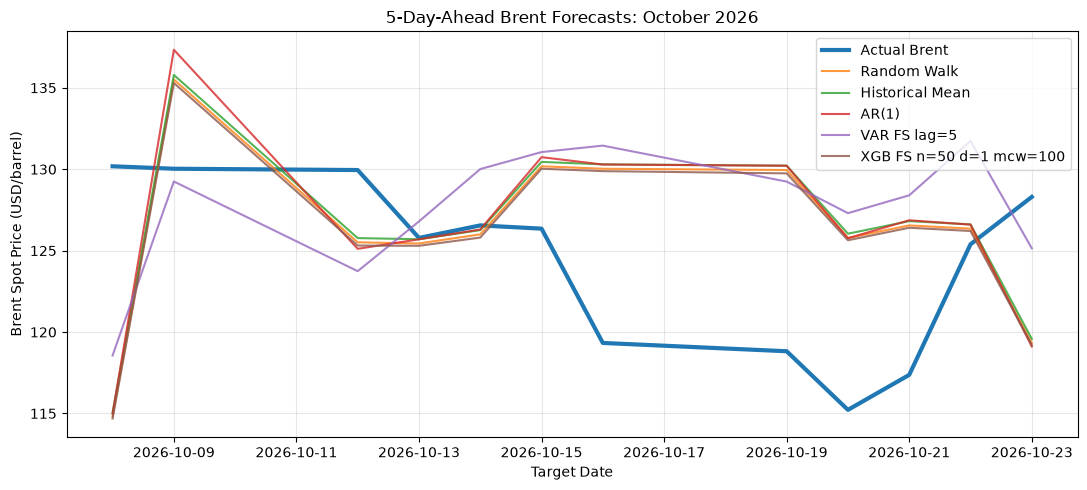

In [15]:
plot_forecasts(test_results, "5-Day-Ahead Brent Forecasts: October 2026")

In [16]:
test_args = dict(horizon=5, start_date="2026-01-01", end_date="2026-09-30", target_end_date="2026-09-30")

test_results = {
    "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **test_args),
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **test_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **test_args),
    f"VAR FS lag={FS_LAG}": walk_forward(df_var, forecast_funct=var_forecast, cols=FS_VARS, lags=FS_LAG, **test_args),
    best_xgb: walk_forward(df_var, forecast_funct=xgb_forecast, features=feats_fs, **xgb_params[best_xgb], **test_args),
}

test_table = compare_models_staggered(test_results, horizon=5)
for metric in ["MAE", "RMSE", "MAPE"]:
    test_table[f"{metric}_vs_RW_%"] = (1 - test_table[metric] / test_table.loc["Random Walk", metric]) * 100
test_table.round(4).sort_values("MAPE")




,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,...,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days,MAE_vs_RW_%,RMSE_vs_RW_%,MAPE_vs_RW_%
model,,,,,,,,,,,,,,,,,,,,,
Random Walk,7.2934,9.5418,7.4742,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,NaN,0.0000,0.0000,0.0000,0.0000,178,0.0000,0.0000,0.0000
AR(1),7.2971,9.5466,7.4794,0.5217,0.5656,0.6635,0.6106,0.4355,0.3375,0.3803,...,0.3695,1.2134,-0.1773,0.4697,0.7584,43.0382,178,-0.0509,-0.0502,-0.0696
Historical Mean,7.2969,9.5398,7.4803,0.5652,0.5652,1.0000,0.7222,0.0000,0.0000,0.0000,...,0.6959,1.5490,-0.5042,1.0000,1.0000,0.0000,178,-0.0472,0.0215,-0.0816
VAR FS lag=5,7.4522,9.7452,7.6627,0.5435,0.5667,0.8173,0.6693,0.4412,0.1875,0.2632,...,0.6040,1.1241,-0.4817,0.7618,0.8989,27.1820,178,-2.1770,-2.1317,-2.5227
XGB FS n=50 d=1 mcw=100,7.4646,9.8674,7.6706,0.4130,0.4773,0.4038,0.4375,0.3542,0.4250,0.3864,...,0.6564,-1.3969,-0.7230,0.9101,0.4831,12.4584,178,-2.3466,-3.4118,-2.6282


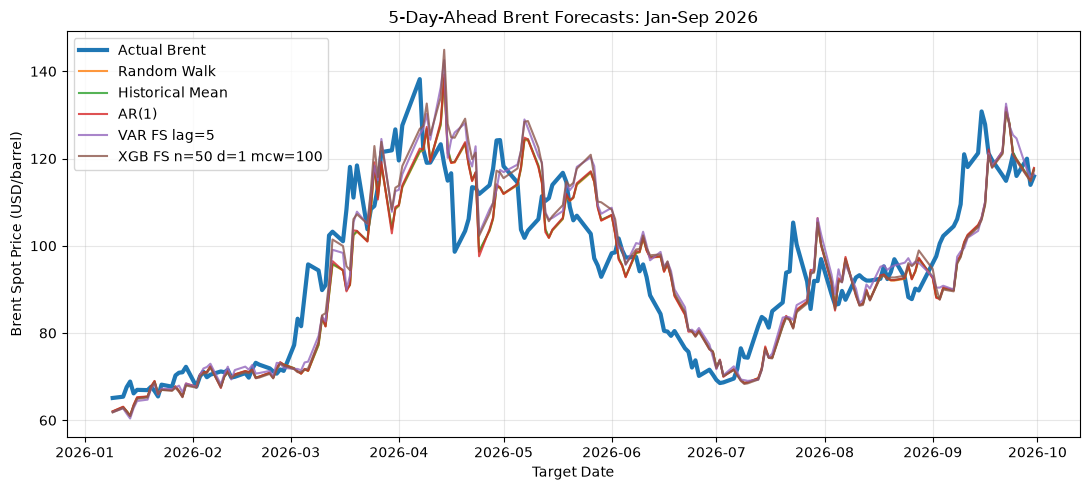

In [17]:
plot_forecasts(test_results, "5-Day-Ahead Brent Forecasts: Jan-Sep 2026")

In [18]:
from src.features import garch_volatility
volatility = garch_volatility(df_var, col="log_return")   # daily GARCH vol, used only to label high/low regimes

val_vol = volatility.reindex(results["Random Walk"]["origin_date"])   # extract vol on each day of the val set
val_median = val_vol.median() # then take median
val_high_mean = val_vol[val_vol >= val_median].mean()
test_vol = volatility.reindex(test_results["Random Walk"]["origin_date"])  # extract vol on each day of the test set
test_vol_mean = volatility.reindex(test_results["Random Walk"]["origin_date"]).mean()   # then take mean

print(f"Validation median vol: {val_median:.2%}")
print(f"Validation high-vol average: {val_high_mean:.2%}")
print(f"Test days in high-vol regime: {(test_vol >= val_median).sum()} of {len(test_vol)}")
print(f"Test average vol: {test_vol_mean:.2%}")


Validation median vol: 1.78%
Validation high-vol average: 2.20%
Test days in high-vol regime: 179 of 184
Test average vol: 4.01%
